# DPI-EVT and prefix anchoring

DPI-EVT infers decoder coefficients from the soil, loading and observed pressure
prefix. The +A variant starts continuation at the measured prefix level. Compare
their fitting settings, first-fold errors and recorded learning histories below.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:06:52+00:00
Inputs: included aggregate tables and public external extracts


## Architecture and fitting settings

In [2]:
MODELS = ['dpi_evt', 'dpi_evt_A']
settings = pd.read_csv(TABLES / "model_settings.csv")
display(settings[settings.model.isin(MODELS)].drop(columns="kwargs"))
from dpi_evt.experiments.final_run import RunSettings
display(pd.Series(vars(RunSettings()), name="Fixed main protocol"))

,model,hidden_width,max_epochs,stored_parameters
5,dpi_evt,160.0,200.0,340531.0
6,dpi_evt_A,160.0,200.0,340531.0


smoke              False
n_splits               5
n_repeats              3
seed                  42
mc_samples            64
baseline_epochs      120
physics_epochs       200
patience              25
Name: Fixed main protocol, dtype: object

## First-fold evaluation and learning history

These are first-fold results. The main comparison pools out-of-fold predictions within each repeat.

,model,Traj_RMSE_continuation,N_liq_logMAE_liq,N_liq_IBS,Coverage_90
5,DPI-EVT,0.0918,0.3346,0.0330,0.7129
6,DPI-EVT +A,0.0747,0.3150,0.0341,0.7586


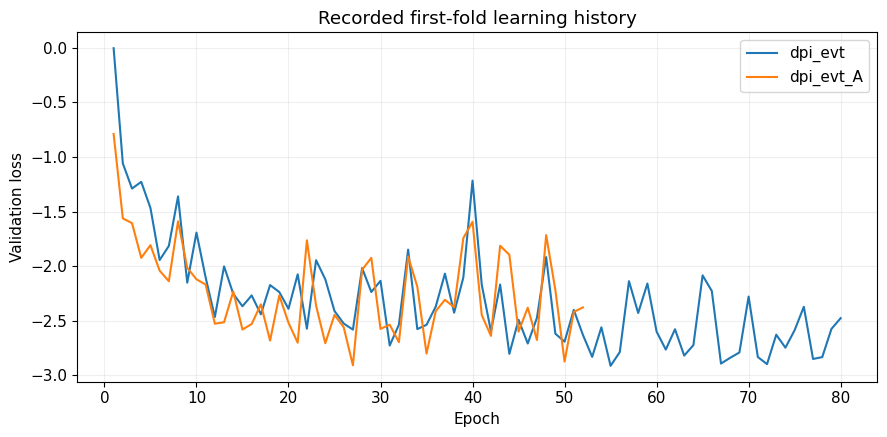

In [3]:
preview = pd.read_csv(TABLES / "training_preview.csv")
display(preview[preview.model_key.isin(MODELS)].drop(columns="model_key").round(4))
history = pd.read_csv(TABLES / "learning_history.csv")
fig, ax = plt.subplots()
for model in MODELS:
    h = history[history.model.eq(model)]
    if len(h): ax.plot(h.epoch, h.val_loss, label=model)
if ax.lines:
    ax.set(xlabel="Epoch", ylabel="Validation loss", title="Recorded first-fold learning history")
    ax.legend(); fig.tight_layout(); plt.show()
else:
    plt.close(fig)
    print("This estimator has no neural epoch history.")

## Refit with authorized inputs

After preparing the laboratory data, set `RUN_TRAINING=True`. The cell uses the study splits and writes fits to the local output directories ignored by Git.

In [4]:
RUN_TRAINING = False
if RUN_TRAINING:
    from dpi_evt.experiments.final_run import notebook_run, preflight
    display(preflight(ROOT))
    run = notebook_run(ROOT)
    display(run.train_preview(MODELS))
else:
    print("Set RUN_TRAINING=True to fit with the prepared laboratory data.")

Set RUN_TRAINING=True to fit with the prepared laboratory data.
